# 演習3：H₂/JWの4 qubitから、Trotter回路とBPDEへ

H₂/STO-3G、R=0.735 Å、2電子・2空間軌道は演習2と同じです。
今回は**4スピン軌道の占有をそのまま残すJW表現**を使い、S₀・S₁・S₂・T₀を扱います。
系4＋補助1 qubitでBPDEに集中し、状態準備は厳密に固定して時間発展だけを近似します。

| 順序 | 数式・回路・計算の対応 |
|---|---|
| 占有とJW変換 | 4ビットの配置、Zの符号列、Pauli文字列 |
| 厳密準備 | 既知の固有振幅をRy/CXで作り、粒子数・スピン・位相を照合 |
| Pauli文字列の指数関数 | 基底変換→CXでパリティ集計→Rz→逆操作 |
| Trotter分解 | 1項の回路を時間順に並べ、厳密行列と近似誤差を比較 |
| BPDE | 準備・逆準備を保ったまま、発展のみ差し替え、全0信号と費用を比較 |

本冊は内蔵データだけで実行できます。Julia・PySCF・IBMアカウントは不要です。
密行列の厳密計算は小規模系での検証用です。全結果はこの固定模型の値で、実験値ではありません。

In [1]:
# 初回だけ必要に応じてコメントを外して実行し、カーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"

In [2]:
"""Small dense verification helpers; optimization itself is the upstream Julia code.
Qiskit little endian, system q0..q3; BPDE ancilla q4.
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Operator, Statevector, SparsePauliOp

TAU = 2*np.pi

def state_prep(name, theta):
    qc = QuantumCircuit(4, name=f'prep_{name}')
    if name in ('T+', 'T-'):
        for q in ([0,1] if name == 'T+' else [2,3]):
            qc.ry(np.pi, q)
        return qc
    base, pivot, angle = {
        'S0': (5,1,theta), 'S2': (5,1,theta+np.pi),
        'S1': (6,0,np.pi/2), 'T': (6,0,-np.pi/2),
        'HF': (5,1,0.),
    }[name]
    for q in range(4):
        if base >> q & 1:
            qc.ry(np.pi, q)
    qc.ry(angle, pivot)
    for q in range(4):
        if q != pivot:
            qc.cx(pivot, q)
    return qc

def joint_prep(target, theta):
    """Exactly (|0> S0 + |1> target)/sqrt(2), including relative phase."""
    c = int(target in ('S1','T'))
    angle = {'S2':theta+np.pi, 'S1':np.pi/2, 'T':-np.pi/2}[target]
    qc = QuantumCircuit(5, name=f'joint_S0_{target}')
    # The minus compensates the open-shell encoder's branch phase.
    qc.ry(-np.pi/2 if c else np.pi/2, 4)
    if c:
        qc.cx(4,1)
    # Exact controlled angle selection with two Ry and two CX.
    qc.ry((theta+angle)/2,0); qc.cx(4,0)
    qc.ry((theta-angle)/2,0); qc.cx(4,0)
    # Common reversible encoder: b=q0, c=q1 -> configurations 5/10 or 6/9.
    qc.cx(0,1); qc.cx(0,2); qc.cx(0,3); qc.cx(1,0); qc.cx(2,0)
    qc.ry(np.pi,0); qc.ry(np.pi,2)
    return qc

def spin_operators():
    a=[]
    for q in range(4):
        op=np.zeros((16,16))
        for n in range(16):
            if n>>q&1:
                op[n^(1<<q),n]=(-1)**((n&((1<<q)-1)).bit_count())
        a.append(op)
    number=sum(x.T@x for x in a)
    sz=(a[0].T@a[0]+a[1].T@a[1]-a[2].T@a[2]-a[3].T@a[3])/2
    plus=a[0].T@a[2]+a[1].T@a[3]
    s2=sz@sz+(plus@plus.T+plus.T@plus)/2
    return number, sz, s2

def brickwall(arrays, depth):
    qc=QuantumCircuit(4, name=f'author_d{depth}')
    for layer in range(1,depth+1):
        starts=range(0,3,2) if layer%2 else range(1,3,2)
        for unit,start in enumerate(starts,1):
            gate=arrays[f'h2_d{depth}_MPO_depth{layer}_{unit}']
            np.testing.assert_allclose(gate.conj().T@gate,np.eye(4),atol=1e-10)
            qc.unitary(gate,[start,start+1],label=f'G{layer}.{unit}')
    return qc

def contract_author_mpo(arrays):
    """Actual exported cores; physical axes right,left; site 1 is q0."""
    cores=[arrays[f'reference_core_{j}'] for j in range(1,5)]
    tensor=cores[0]
    for core in cores[1:]:
        tensor=np.tensordot(tensor,core,axes=(-1,0))
    # Julia reshape is column-major: q0 is fastest within each physical group.
    return tensor.transpose(0,2,4,6,1,3,5,7).reshape(16,16,order='F')

def dense_trotter(h,dt,slices=100,order=2):
    p=SparsePauliOp.from_operator(Operator(h),atol=1e-12)
    terms=[(float(c.real), SparsePauliOp(label).to_matrix()) for label,c in zip(p.paulis.to_labels(),p.coeffs)]
    step=np.eye(16,dtype=complex)
    sequence=terms+terms[::-1] if order==2 else terms
    factor=2 if order==2 else 1
    for c,pauli in sequence:
        angle=c*dt/slices/factor
        step=(np.cos(angle)*np.eye(16)-1j*np.sin(angle)*pauli)@step
    return np.linalg.matrix_power(step,slices)

def rel_error(a,b):
    return float(np.linalg.norm(a-b)/np.linalg.norm(b))

def unitary_defect(u):
    return float(np.linalg.norm(u.conj().T@u-np.eye(len(u)))/np.sqrt(len(u)))

def controlled_matrix(u):
    # The first qarg is the low bit: control=0 -> I, control=1 -> U.
    cu=np.eye(2*len(u),dtype=complex)
    cu[1::2,1::2]=u
    return cu

def inverse_qft(m):
    qc=QuantumCircuit(m,name='QFT_dg')
    for j in range(m//2): qc.swap(j,m-1-j)
    for j in range(m):
        for k in range(j): qc.cp(-np.pi/2**(j-k),j,k)
        qc.h(j)
    return qc

def qpe_circuit(prep,u,m=3):
    qc=QuantumCircuit(m+4)
    qc.compose(prep,range(m,m+4),inplace=True)
    for r in range(m):
        qc.h(r)
        qc.append(UnitaryGate(controlled_matrix(np.linalg.matrix_power(u,2**r)),label=f'c-U^{2**r}'),[r]+list(range(m,m+4)))
    qc.compose(inverse_qft(m),range(m),inplace=True)
    return qc

def qpe_distribution(prep,u,m=3):
    return Statevector.from_instruction(qpe_circuit(prep,u,m)).probabilities(range(m))

def qpe_formula(phi,m):
    M=2**m
    return abs(np.mean(np.exp(1j*TAU*np.outer(np.arange(M),phi-np.arange(M)/M)),axis=0))**2

def iqpe_tree(psi,u,m=3,reprepare=False):
    branches=[(0,1.,np.asarray(psi,complex))]
    for ell,r in enumerate(reversed(range(m))):
        up=np.linalg.matrix_power(u,2**r);new=[]
        for y,weight,state in branches:
            incoming=psi if reprepare else state
            beta=-TAU*2**r*y/2**m
            for bit in (0,1):
                out=(incoming+(-1)**bit*np.exp(1j*beta)*up@incoming)/2
                prob=float(np.vdot(out,out).real)
                if prob>1e-14: new.append((y+bit*2**ell,weight*prob,out/np.sqrt(prob)))
        branches=new
    p=np.zeros(2**m)
    for y,w,_ in branches: p[y]+=w
    return p

def iqpe_dynamic(prep,u,m=3):
    from qiskit import QuantumRegister,ClassicalRegister
    a=QuantumRegister(1,'a');s=QuantumRegister(4,'s');c=ClassicalRegister(m,'bits')
    qc=QuantumCircuit(a,s,c);qc.compose(prep,s,inplace=True)
    for ell,r in enumerate(reversed(range(m))):
        if ell: qc.reset(a[0])
        qc.h(a[0]);qc.append(UnitaryGate(controlled_matrix(np.linalg.matrix_power(u,2**r)),label=f'c-U^{2**r}'),[a[0]]+list(s))
        for old in range(ell):
            with qc.if_test((c[old],1)): qc.p(-TAU*2**r*2**old/2**m,a[0])
        qc.h(a[0]);qc.measure(a[0],c[ell])
    return qc

def bpe_circuit(prep,u,L=1,beta=0):
    qc=QuantumCircuit(5);qc.compose(prep,range(4),inplace=True);qc.h(4)
    qc.append(UnitaryGate(controlled_matrix(np.linalg.matrix_power(u,L)),label=f'c-U^{L}'),[4,0,1,2,3])
    qc.p(beta,4);qc.h(4)
    return qc

def bpe_probability(psi,u,L,beta):
    amp=np.vdot(psi,np.linalg.matrix_power(u,L)@psi)
    return float((1+np.real(np.exp(1j*beta)*amp))/2)

def bpde_circuit(target,theta,u,L=1,beta=0):
    prep=joint_prep(target,theta)
    qc=prep.copy()
    qc.unitary(np.linalg.matrix_power(u,L),range(4),label=f'U^{L}')
    qc.p(beta,4);qc.compose(prep.inverse(),inplace=True)
    return qc

def bpde_probability(target,theta,u,L,beta,all_zero=True):
    vector=Statevector.from_instruction(bpde_circuit(target,theta,u,L,beta)).data
    return float(abs(vector[0])**2 if all_zero else sum(abs(vector[:16])**2))

def single_phase(phi,L,beta):
    return .5*(1+np.cos(TAU*L*np.asarray(phi)+beta))

def bayes(grid,settings,probability,shots=256,seed=20261108,expected=False):
    rng=np.random.default_rng(seed);logp=np.zeros_like(grid);history=[];records=[]
    for L,beta in settings:
        truth=float(np.clip(probability(L,beta),0,1))
        n0=shots*truth if expected else int(rng.binomial(shots,truth))
        p=np.clip(single_phase(grid,L,beta),1e-12,1-1e-12)
        logp+=n0*np.log(p)+(shots-n0)*np.log1p(-p);logp-=max(logp)
        post=np.exp(logp);post/=post.sum();history.append(post)
        records.append((L,beta,n0,shots,truth))
    return np.asarray(history),records

def summary(grid,p):
    lo,hi=np.interp([.025,.975],np.cumsum(p),grid)
    return float(grid[np.argmax(p)]),float(lo),float(hi)

def time_comparison(probability,target,label,seed=42):
    grid=(np.arange(32768)+.5)/32768
    plans={'L=1':[1]*6,'Staged':[1,2,4,8,16,32],'L=32':[32]*6}
    fig,axes=plt.subplots(2,3,figsize=(12,6))
    results={}
    for k,(name,lengths) in enumerate(plans.items()):
        settings=[(L,b) for L in lengths for b in [np.pi/5,np.pi/5-np.pi/2]]
        hist,records=bayes(grid,settings,probability,seed=seed+k)
        est,lo,hi=summary(grid,hist[-1]);widths=[summary(grid,p)[2]-summary(grid,p)[1] for p in hist[1::2]]
        for row in (0,1):
            axes[row,k].plot(grid,hist[-1]*len(grid));axes[row,k].axvline(target,c='C3',ls='--')
            axes[row,k].set(xlabel='Phase',ylabel='Posterior density',title=name)
        axes[1,k].set_xlim(target-.025,target+.025)
        print(name,'shots=',256*len(settings),'sum(R L)=',256*sum(lengths)*2,'MAP=',est,'95% width=',hi-lo)
        results[name]=(settings,hist,widths)
    fig.suptitle(label);plt.tight_layout();plt.show()
    fig,ax=plt.subplots(figsize=(7,3))
    for name,(_,_,widths) in results.items(): ax.semilogy(np.arange(1,7)*512,widths,'o-',label=name)
    ax.set(xlabel='Cumulative shots',ylabel='Global 95% interval width',title=label);ax.legend();plt.show()
    # L=32 aliases are exactly unresolved for the uniform prior.
    np.testing.assert_allclose(results['L=32'][1][-1].reshape(32,-1).sum(axis=1),1/32,atol=1e-9)
    for k,name in enumerate(['L=1','Staged']):
        settings=results[name][0];rng=np.random.default_rng(seed+100+k)
        probs=[probability(L,b) for L,b in settings]
        counts=rng.binomial(256,np.clip(probs,0,1),size=(64,len(settings)))
        model=np.array([np.clip(single_phase(grid,L,b),1e-12,1-1e-12) for L,b in settings])
        logp=counts@np.log(model)+(256-counts)@np.log1p(-model);logp-=logp.max(axis=1,keepdims=True)
        post=np.exp(logp);post/=post.sum(axis=1,keepdims=True)
        estimates=grid[np.argmax(post,axis=1)]
        err=(estimates-target+.5)%1-.5
        print(name,'64-trial circular RMSE=',np.sqrt(np.mean(err**2)))
    return results

def exact_two_qubit_synthesis(matrix):
    """Avoid default KAK specialization tolerances; preserve the input global phase.
    Try 0/1/2/3 CX decompositions of the unspecialized Weyl target, accept only
    a matrix-verified representation. This changes compilation, not optimization.
    """
    from qiskit.circuit.library import CXGate
    from qiskit.synthesis import TwoQubitBasisDecomposer, TwoQubitWeylDecomposition, OneQubitEulerDecomposer
    target=TwoQubitWeylDecomposition(matrix,fidelity=None)
    decomposer=TwoQubitBasisDecomposer(CXGate(),basis_fidelity=1.,euler_basis='ZSX',pulse_optimize=False)
    euler=OneQubitEulerDecomposer('ZSX')
    methods=[decomposer.decomp0,decomposer.decomp1,decomposer.decomp2_supercontrolled,decomposer.decomp3_supercontrolled]
    for count,method in enumerate(methods):
        locals_=method(target._inner_decomposition)
        circuit=QuantumCircuit(2)
        for pair in range(count+1):
            circuit.compose(euler(locals_[2*pair],simplify=False),[0],inplace=True)
            circuit.compose(euler(locals_[2*pair+1],simplify=False),[1],inplace=True)
            if pair<count:circuit.cx(0,1)
        actual=Operator(circuit).data
        # Correct the circuit's phase itself; the error metric never discards phase.
        circuit.global_phase+=float(np.angle(np.trace(actual.conj().T@matrix)))
        if np.max(abs(Operator(circuit).data-matrix))<2e-11:
            return circuit
    raise AssertionError('Exact two-qubit synthesis did not preserve its matrix')

def compile_exact(qc):
    expanded=QuantumCircuit(qc.num_qubits)
    expanded.global_phase=qc.global_phase
    for instruction in qc.data:
        qargs=[qc.find_bit(q).index for q in instruction.qubits]
        if instruction.operation.name=='unitary' and len(qargs)==2:
            expanded.compose(exact_two_qubit_synthesis(instruction.operation.to_matrix()),qargs,inplace=True)
        else:
            expanded.append(instruction.operation,qargs)
    compiled=transpile(expanded,basis_gates=['rz','sx','x','cx'],optimization_level=1,seed_transpiler=7)
    np.testing.assert_allclose(Operator(compiled).data,Operator(qc).data,atol=1e-10)
    return compiled

import base64, io
with np.load(io.BytesIO(base64.b64decode('UEsDBC0AAAAIAAAAIQAHLXw+//////////8PABQAaGFtaWx0b25pYW4ubnB5AQAQAIAIAAAAAAAALwEAAAAAAACb7BfqGxDJyFDGUK2eklqcXKRupaBuk2ahrqOgnpZfVFKUmBefX5SSChJ3S8wpTgWKF2ckFqQC+RqGZjoKhmaaOgq1CmQCLoZBAgKOff7/TfLL/vYZXoVsqzfb0Nv+1Rr77Fi2N+zZt3qGf7fxvf30th8dnHioUXvx5ecBdwcsXnDJ0yu+2B0SeixS/u7vqdVlmLhmJ4Z9MPGTMp9fHNA4bk9t+6v/R1gEhPbb6NVxJexk+YgRHjB7JYRK1X1ZDtA8PPJeHJ36aeInnPEyu+VZnhDrYYrdAcsXuOTplV9g4Y8rfmHxQqvwh9mr1tu/Oq13CYb5MPFd8U/lA5LP0zw8Zqxe9cTWYwNOf/7ct//pgznXBrz8GCzlGCy/UCtfkApg8TVY4mXJCQXVitzT9gBQSwMELQAAAAgAAAAhACdbaoz//////////wsAFABudWNsZWFyLm5weQEAEACIAAAAAAAAAEsAAAAAAAAAm+wX6hsQychQxlCtnpJanFykbqWgbpNmoa6joJ6WX1RSlJgXn1+UkgoSd0vMKU4FihdnJBakAvkamjoKtQoUAS756JVZfzif2wMAUEsDBC0AAAAIAAAAIQAaCM5j//////////8QABQAZmNpX2VuZXJnaWVzLm5weQEAEACgAAAAAAAAAGYAAAAAAAAAm+wX6hsQychQxlCtnpJanFykbqWgbpNmoa6joJ6WX1RSlJgXn1+UkgoSd0vMKU4FihdnJBakAvkaJjqaOgq1ChQALr7VgRfSjT7tz81Y0b/s5IP9Mhm7cySuHtm/JqNiFdv6+/YAUEsDBC0AAAAIAAAAIQAdsfcn//////////8NABQAZmNpX3NwaW5zLm5weQEAEACgAAAAAAAAAE0AAAAAAAAAm+wX6hsQychQxlCtnpJanFykbqWgbpNmoa6joJ6WX1RSlJgXn1+UkgoSd0vMKU4FihdnJBakAvkaJjqaOgq1ChQALgYoYIRQDgxoAABQSwMELQAAAAgAAAAhAJom90P//////////woAFABsYWJlbHMubnB5AQAQAHABAAAAAAAAZgAAAAAAAACb7BfqGxDJyFDGUK2eklqcXKRupaBuE2qirqOgnpZfVFKUmBefX5SSChJ3S8wpTgWKF2ckFqQC+RqGpjqaOgq1CuQDLk8GBgZcOAoHG8aPwiOHTsPYEThwJBrGJY7LLlxuikJTAwBQSwMELQAAAAgAAAAhADINua3//////////xAAFABjb2VmZmljaWVudHMubnB5AQAQAHABAAAAAAAAogAAAAAAAACb7BfqGxDJyFDGUK2eklqcXKRupaBuk2xopq6joJ6WX1RSlJgXn1+UkgqScEvMKU4FihdnJBakAvkahqY6mjoKtQpkA65tT9oDmT683M8ABb+q9jfLcx2zh/GV1rL31j49A5e/Y3skSvHLPrj8bzT1hjP5nmfNP4rQ/2zecwcXBP+kzOcXBzSW4+I3EOAzqKC5RwXN/AvB8923RyHccw/NvQBQSwECLQMtAAAACAAAACEABy18Pi8BAACACAAADwAAAAAAAAAAAAAAgAEAAAAAaGFtaWx0b25pYW4ubnB5UEsBAi0DLQAAAAgAAAAhACdbaoxLAAAAiAAAAAsAAAAAAAAAAAAAAIABcAEAAG51Y2xlYXIubnB5UEsBAi0DLQAAAAgAAAAhABoIzmNmAAAAoAAAABAAAAAAAAAAAAAAAIAB+AEAAGZjaV9lbmVyZ2llcy5ucHlQSwECLQMtAAAACAAAACEAHbH3J00AAACgAAAADQAAAAAAAAAAAAAAgAGgAgAAZmNpX3NwaW5zLm5weVBLAQItAy0AAAAIAAAAIQCaJvdDZgAAAHABAAAKAAAAAAAAAAAAAACAASwDAABsYWJlbHMubnB5UEsBAi0DLQAAAAgAAAAhADINua2iAAAAcAEAABAAAAAAAAAAAAAAAIABzgMAAGNvZWZmaWNpZW50cy5ucHlQSwUGAAAAAAYABgBlAQAAsgQAAAAA')), allow_pickle=False) as saved:
    DATA = {k:saved[k].copy() for k in saved.files}
from IPython.display import display
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter, SuzukiTrotter

def draw(qc):
    display(qc.draw(output='mpl', fold=100)); plt.close('all')


## 0．JWで系4 qubitになる理由

空間軌道g,uのそれぞれにα,βのスピンがあり、スピン軌道は4個です。
$$ (q_0,q_1,q_2,q_3)=(g\alpha,u\alpha,g\beta,u\beta),\quad n_p=0\text{ または }1.$$
JW表現は1スピン軌道の占有を1 qubitへ対応させます。2電子だから2 qubit、という数え方ではありません。
ケットは$|q_3q_2q_1q_0\rangle$、配列添字は$\sum_p2^pn_p$です。

| 配置 | 占有ケット | 配列添字 | 前冊との対応 |
|---|---|---:|---|
| gα,gβ | 0101 | 5 | Dg＝論理0 |
| uα,uβ | 1010 | 10 | Du＝論理1 |
| uα,gβ | 0110 | 6 | O1、開殻 |
| gα,uβ | 1001 | 9 | O2、開殻 |
| gα,uα | 0011 | 3 | 三重項M_S=+1 |
| gβ,uβ | 1100 | 12 | 三重項M_S=−1 |

4 qubitのFock空間は$2^4=16$次元で、電子数0〜4の配置を含みます。
電子数2は6次元、その中のM_S=0は4次元です。本冊の回路は16次元を保持し、粒子数2の状態を準備します。
前冊はDg/Duの不変ブロックだけを厳密に符号化した1 qubitで、S₁/T₀を含みませんでした。
本冊では量子ビット削減やtaperingを行いません。

### 課題1：qubit数と電子数

なぜ2電子で4 qubitを使うのか。1 qubit版は電子を一つ捨てていたのか。

<details><summary>解答例</summary>

qubitが表すのは電子の番号ではなく、4スピン軌道それぞれの占有です。
1 qubit版も2電子のまま、Dg/Duの2次元だけを別の論理基底に写していました。
四つの中性状態だけを抽象的に符号化すれば2 qubitで足りますが、ここでは全Fock空間を保持するJWの4 qubitを使います。

</details>

## 1．JW変換：フェルミオンの符号をZの列で表す

電子Hamiltonianは生成・消滅演算子で
$$H=\sum_{pq}h_{pq}a_p^\dagger a_q+\frac{1}{2}\sum_{pqrs}v_{pqrs}a_p^\dagger a_q^\dagger a_s a_r$$
と書けます。ここでvはスピン軌道の二電子積分$\langle pq|r_{12}^{-1}|rs\rangle$です。
フェルミオンは$\{a_p,a_q^\dagger\}=\delta_{pq}I$、$\{a_p,a_q\}=0$を満たします。
異なるqubitの単純な昇降演算子は可換なので、そのままではこの符号を表せません。

$$a_p=\left(\prod_{k<p}Z_k\right)\frac{X_p+iY_p}{2},\qquad
 a_p^\dagger=\left(\prod_{k<p}Z_k\right)\frac{X_p-iY_p}{2},\qquad
 n_p=a_p^\dagger a_p=\frac{I-Z_p}{2}.$$
Zの列は、pより前の占有数が奇数なら−1を掛けます。

例：$a_2|0101\rangle=-|0001\rangle$です。q₂を消す際、手前のq₀が占有されているため負号が付きます。
この代数をHamiltonianへ代入・展開すると$H=\sum_j c_jP_j$になります。
JW変換は厳密な表現の変更で、Trotterの時間発展近似はまだ入っていません。

次セルはJW式のaₚと、占有ビットから直接作る行列を照合します。
さらに反交換関係とnₚを確認します。Qiskitの文字列は高位qubitからなので、Z₀は`IIIZ`です。

In [3]:
def pauli_on(qubit,letter):
    label=['I']*4;label[3-qubit]=letter
    return SparsePauliOp(''.join(label)).to_matrix()

ANNIHILATORS=[]
for p in range(4):
    prefix=np.eye(16,dtype=complex)
    for k in range(p):prefix=prefix@pauli_on(k,'Z')
    mapped=prefix@(pauli_on(p,'X')+1j*pauli_on(p,'Y'))/2
    direct=np.zeros((16,16),complex)
    for n in range(16):
        if n>>p&1:direct[n^(1<<p),n]=(-1)**((n&((1<<p)-1)).bit_count())
    np.testing.assert_allclose(mapped,direct,atol=1e-12)
    np.testing.assert_allclose(mapped.conj().T@mapped,(np.eye(16)-pauli_on(p,'Z'))/2,atol=1e-12)
    ANNIHILATORS.append(mapped)
for p in range(4):
    for q in range(4):
        ap,aq=ANNIHILATORS[p],ANNIHILATORS[q]
        np.testing.assert_allclose(ap@aq+aq@ap,0,atol=1e-12)
        np.testing.assert_allclose(ap@aq.conj().T+aq.conj().T@ap,(p==q)*np.eye(16),atol=1e-12)
print('a2 |0101> ->',ANNIHILATORS[2][:,5])
print('JW signs, anticommutators and occupation operators checked')

a2 |0101> -> [ 0.+0.j -1.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j
  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j  0.+0.j]
JW signs, anticommutators and occupation operators checked


### 課題2：Zの符号列

1. Zの列を省いたqubitの昇降演算子を、異なる軌道間で使ってよいか。
2. `IZII`と`IIIZ`はどのqubitのZか。

<details><summary>解答例</summary>

1. 省くと異なる軌道の演算子が可換になり、フェルミオンの反交換関係を満たしません。
2. IZIIはq₂、IIIZはq₀です。文字列の位置とqubit番号を同じ向きに数えないようにします。

</details>

## 2．四つの厳密状態をRy/CXで作る

前冊と同じ位相規約で
$$\begin{aligned}
S_0&=\cos(\theta/2)|0101\rangle+\sin(\theta/2)|1010\rangle,\\
S_2&=-\sin(\theta/2)|0101\rangle+\cos(\theta/2)|1010\rangle,\\
S_1&=(|0110\rangle+|1001\rangle)/\sqrt2,\\
T_0(M_S=0)&=(|0110\rangle-|1001\rangle)/\sqrt2.
\end{aligned}$$
S₁とT₀の占有確率は同じですが相対符号が違い、S²は0と2です。コードでは三重項を`T`と書きます。

S₀の準備を時間順に追います。

```text
|0000> -- Ry_q0(π), Ry_q2(π) --> |0101>
       -- Ry_q1(θ) --> cos(θ/2)|0101> + sin(θ/2)|0111>
       -- CX(q1→q0,q2,q3) --> cos(θ/2)|0101> + sin(θ/2)|1010>
```

S₂は角度をθ+πにします。S₁/T₀は基準配置を0110、回転のqubitをq₀、角度を±π/2へ変えます。
既知の二つの配置の振幅から角度が決まるので、このH₂では短い厳密回路になります。
汎用の未知な多電子状態を同じ費用で準備できるという主張ではありません。
次セルは、折り畳みの共通関数に含まれる準備処理を、学習用にそのまま表示・定義します。

In [4]:
def state_prep(name, theta):
    qc = QuantumCircuit(4, name=f'prep_{name}')
    if name in ('T+', 'T-'):
        for q in ([0,1] if name == 'T+' else [2,3]):
            qc.ry(np.pi, q)
        return qc
    base, pivot, angle = {
        'S0': (5,1,theta), 'S2': (5,1,theta+np.pi),
        'S1': (6,0,np.pi/2), 'T': (6,0,-np.pi/2),
        'HF': (5,1,0.),
    }[name]
    for q in range(4):
        if base >> q & 1:
            qc.ry(np.pi, q)
    qc.ry(angle, pivot)
    for q in range(4):
        if q != pivot:
            qc.cx(pivot, q)
    return qc

### 2.1．粒子数・全スピン・固有方程式を照合する

Hは電子Hamiltonianで、核間反発ENUCを加えると全エネルギーです。
本冊の基本時間は**Δt=0.1**原子単位です（前冊は1）。同じ分子でも位相は変わるため、エネルギーで比較します。
次セルは各準備回路の振幅を取り、Hψ=Eψ、N=2、S²=0/2を確認します。
15項のPauli和も内蔵Hamiltonianに戻ることを照合します。
表示する4×4ブロックは演習2と同じ(Dg,Du,O1,O2)順です。
コードのSPIN2はS²演算子の行列で、状態名の文字列'S2'とは区別します。

In [5]:
H=DATA['hamiltonian']; ENUC=float(DATA['nuclear']); DT=.1
PAULI=SparsePauliOp(DATA['labels'].tolist(),DATA['coefficients'])
np.testing.assert_allclose(PAULI.to_matrix(),H,atol=1e-12)
theta=-np.arctan2(2*H[5,10],H[10,10]-H[5,5])
PREPS={s:state_prep(s,theta) for s in ['S0','S1','S2','T','T+','T-','HF']}
STATES={s:Statevector.from_instruction(p).data for s,p in PREPS.items()}
ENERGIES={s:float(np.vdot(v,H@v).real) for s,v in STATES.items()}
PHASES={s:(-e*DT/TAU)%1 for s,e in ENERGIES.items()}
U=expm(-1j*H*DT)
N,SZ,SPIN2=spin_operators()
for s in ['S0','S1','S2','T','T+','T-']:
    v=STATES[s]
    assert np.linalg.norm(H@v-ENERGIES[s]*v)<1e-10
    np.testing.assert_allclose(np.vdot(v,N@v),2,atol=1e-12)
    np.testing.assert_allclose(np.vdot(v,SPIN2@v),0 if s.startswith('S') else 2,atol=1e-12)
    print(s,'E total=',ENERGIES[s]+ENUC,'S²=',np.vdot(v,SPIN2@v).real,'Sz=',np.vdot(v,SZ@v).real)
print('15 Pauli terms (including I):')
for label,c in zip(PAULI.paulis.to_labels(),PAULI.coeffs):print(label, float(c.real))
print('Nalpha=Nbeta=1 block, basis Dg=0101,Du=1010,O1=0110,O2=1001:\n',H[np.ix_([5,10,6,9],[5,10,6,9])])
print('theta=',theta,'nuclear=',ENUC)

S0 E total= -1.1373060357534004 S²= 5.624099184981967e-33 Sz= 0.0
S1 E total= -0.16275315579588445 S²= 1.232595164407831e-32 Sz= 0.0
S2 E total= 0.4950577416181079 S²= 5.6240991849819653e-33 Sz= 0.0
T E total= -0.5246155553643471 S²= 1.9999999999999998 Sz= 0.0
T+ E total= -0.5246155553643473 S²= 2.0 Sz= 1.0
T- E total= -0.5246155553643473 S²= 2.0 Sz= -1.0
15 Pauli terms (including I):
IIII -0.8105479805373281
IIIZ 0.1721839326191555
IIZI -0.22575349222402347
IIZZ 0.12091263261776625
IZII 0.17218393261915552
IZIZ 0.1689275387008791
IZZI 0.16614543256382414
XXXX 0.04523279994605784
XXYY 0.04523279994605784
YYXX 0.04523279994605784
YYYY 0.04523279994605784
ZIII -0.22575349222402352
ZIIZ 0.1661454325638242
ZIZI 0.17464343068300403
ZZII 0.12091263261776627
Nalpha=Nbeta=1 block, basis Dg=0101,Du=1010,O1=0110,O2=1001:
 [[-1.83696799e+00  1.80931200e-01  3.56299539e-16  3.56299539e-16]
 [ 1.80931200e-01 -2.45218292e-01  1.42610561e-16  1.42610561e-16]
 [ 5.43545336e-17  4.44555567e-16 -1.06365

### 2.2．厳密準備の回路と振幅

次セルで4状態の回路と振幅を表示します。個別準備は配置を作るRy(π)も含めて3 Ry＋3 CXです。
粒子数2やスピンの照合だけでなく、符号付きの振幅を式と比べます。
前冊の2×2行列が、今回のHの添字5,10ブロックに残っていることも確認します。

S0 gates: {'ry': 3, 'cx': 3} nonzero amplitudes: {'0101': 0.993760401, '1010': -0.111535939}
S1 gates: {'ry': 3, 'cx': 3} nonzero amplitudes: {'0110': 0.707106781, '1001': 0.707106781}
S2 gates: {'ry': 3, 'cx': 3} nonzero amplitudes: {'0101': 0.111535939, '1010': 0.993760401}
T gates: {'ry': 3, 'cx': 3} nonzero amplitudes: {'0110': 0.707106781, '1001': -0.707106781}


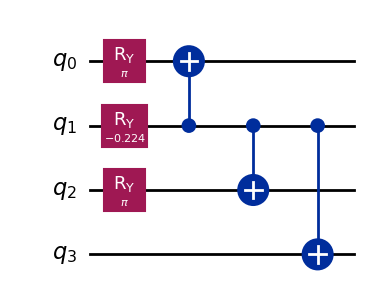

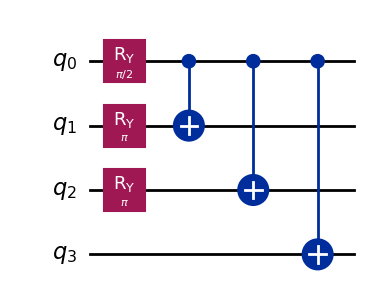

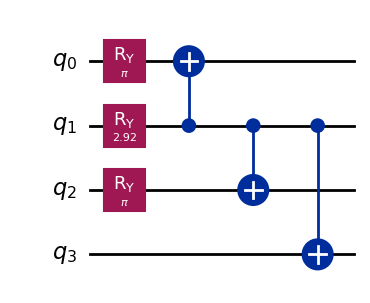

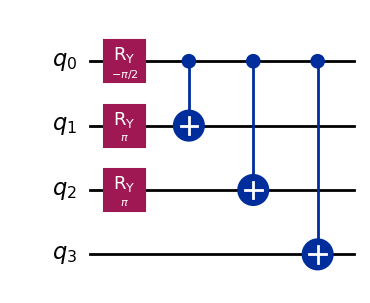

In [6]:
EXPECTED_STATES={
 'S0':np.eye(16)[:,5]*np.cos(theta/2)+np.eye(16)[:,10]*np.sin(theta/2),
 'S2':-np.eye(16)[:,5]*np.sin(theta/2)+np.eye(16)[:,10]*np.cos(theta/2),
 'S1':(np.eye(16)[:,6]+np.eye(16)[:,9])/np.sqrt(2),
 'T':(np.eye(16)[:,6]-np.eye(16)[:,9])/np.sqrt(2)}
for name in ['S0','S1','S2','T']:
    np.testing.assert_allclose(STATES[name],EXPECTED_STATES[name],atol=1e-12)
    print(name,'gates:',dict(PREPS[name].count_ops()),'nonzero amplitudes:',
          {f'{i:04b}':round(float(a.real),9) for i,a in enumerate(STATES[name]) if abs(a)>1e-10})
    draw(PREPS[name])
np.testing.assert_allclose(H[np.ix_([5,10],[5,10])],
    [[-1.836967991202984,.18093119978423136],[.18093119978423136,-.24521829183026772]],atol=1e-12)

### 課題3：厳密準備と時間発展

1. 全16次元でも準備が短い理由は何か。
2. S₀の角度をθ+πにするとどの状態になるか。
3. HFを厳密発展させればS₁やT₀を作れるか。

<details><summary>解答例</summary>

1. 本模型の既知の固有状態は二つの配置だけの重ね合わせで、角度を直接計算できるためです。
2. 係数が−sin(θ/2)、cos(θ/2)になり、直交するS₂になります。
3. HFはDg/Duの不変ブロックにあり、厳密なHの発展だけでは別ブロックのS₁/T₀へ移りません。
BPDEでは初めに別々の状態を準備します。

</details>

## 3．補助の二つの枝へ厳密状態を準備する

$$A_j|0^5\rangle=(|0\rangle_a|S_0\rangle+|1\rangle_a|j\rangle)/\sqrt2.$$
個別状態のfidelityが1でも、二つの枝の相対位相が正しいとは限りません。
次セルでは5 qubitの準備振幅を、上の式と符号まで照合します。
補助はq₄（配列の上位ビット）なので、状態ベクトルは`[S0, j]/sqrt(2)`です。
`joint_prep`は同じRy/CXから作る可逆な回路で、resetは使いません。逆準備はこの実際の回路の逆です。

Joint S0/S1 {'cx': 8, 'ry': 5}
Joint S0/S2 {'cx': 7, 'ry': 5}
Joint S0/T {'cx': 8, 'ry': 5}


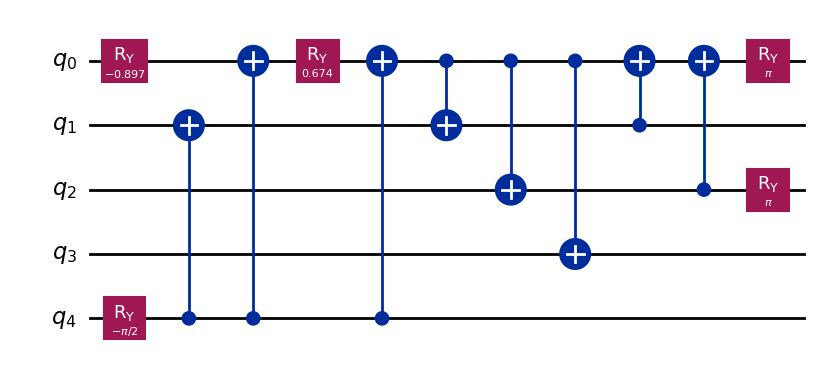

In [7]:
TARGET='T'  # 'S1', 'S2', 'T'を選択。Tは最低三重項のMs=0成分
PAIRS={target:joint_prep(target,theta) for target in ['S1','S2','T']}
for target,a in PAIRS.items():
    expected=np.r_[STATES['S0'],STATES[target]]/np.sqrt(2)
    np.testing.assert_allclose(Statevector.from_instruction(a).data,expected,atol=1e-12)
    inverse=a.compose(a.inverse())
    np.testing.assert_allclose(Statevector.from_instruction(inverse).data,np.eye(32)[:,0],atol=1e-12)
    print('Joint S0/'+target,dict(a.count_ops()))
draw(PAIRS[TARGET])

## 4．厳密発展でBPDEの参照信号を確認する

```text
a=q4: |0> ──┌─────┐────────P(β)──┌──────┐──M_a──┐
            │ A_j │              │ A_j† │       ├─ 全5ビット0を数える
s=q0..3: ───└─────┘──[U^L]───────└──────┘──M_s──┘
```

U=exp(−iHΔt)は補助で制御せず、系4 qubitにだけ作用します。
$$a_k(L)=\langle\psi_k|U^L|\psi_k\rangle,\quad
P(0^5)=\tfrac14|a_0+e^{i\beta}a_j|^2.$$
厳密準備・厳密発展では$\beta=\varepsilon t$、$t=L\Delta t$として
$$P(0^5|\varepsilon)=[1+\cos((\varepsilon-\Delta E)t)]/2.$$
全0の回数は全shotsで割ります。補助だけの0とは一般に異なる事象です。

次セルでは三つのギャップの曲線を比較し、5 qubit回路と余弦式を照合します。
この段階の密行列Uは厳密な参照で、実装費用を無視して実機へ投入する前提ではありません。

Exact gaps / Ha: {'S1': 0.9745528799575158, 'S2': 1.632363777371508, 'T': 0.6126904803890532}


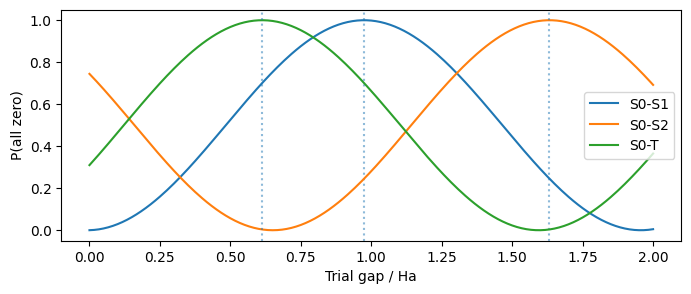

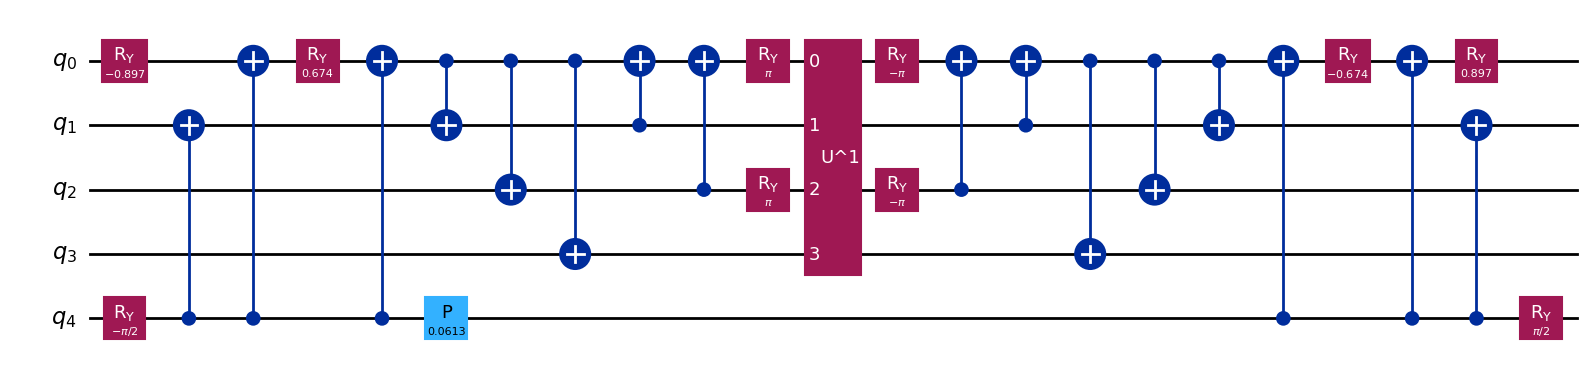

In [8]:
GAPS={s:ENERGIES[s]-ENERGIES['S0'] for s in ['S1','S2','T']}
L=32
trial=np.linspace(0,2,241)
fig,ax=plt.subplots(figsize=(8,3))
for target in GAPS:
    p=np.array([bpde_probability(target,theta,U,L,float(eps*L*DT),True) for eps in trial])
    np.testing.assert_allclose(p,(1+np.cos((trial-GAPS[target])*L*DT))/2,atol=1e-11)
    ax.plot(trial,p,label='S0-'+target)
    ax.axvline(GAPS[target],ls=':',alpha=.5)
ax.set(xlabel='Trial gap / Ha',ylabel='P(all zero)');ax.legend();plt.show();plt.close(fig)
print('Exact gaps / Ha:',GAPS)
draw(bpde_circuit(TARGET,theta,U,L=1,beta=GAPS[TARGET]*DT))

### 課題4：枝の準備とHamiltonianの役割

1. 一重項S₀と三重項T₀の差を測るため、Hへスピンを変える項を足す必要があるか。
2. 準備した二つの枝へ同じ追加定数dIを作用させると、差の信号はどうなるか。
3. Lを増やすと曲線の周期はどうなるか。

<details><summary>解答例</summary>

1. 不要です。最初から補助の枝ごとにS₀とT₀を準備し、同じHで位相を蓄積させます。
2. 共通位相exp(−idt)が絶対値の外へくくれるため、全0確率と差は変わりません。
3. 候補エネルギー差での周期は2π/(LΔt)なので短くなり、別の候補も増えます。
厳密ギャップはS₁≈0.97455288、S₂≈1.63236378、T₀≈0.61269048 Haです。

</details>

## 5．Pauli文字列1項を、RzとCXへ分解する

JW変換後は$H=\sum_jc_jP_j$です。1項なら
$$e^{-ic_jP_j\tau}=\cos(c_j\tau)I-i\sin(c_j\tau)P_j$$
を厳密に回路化できます。Rz(α)=exp(−iαZ/2)なので、回転角は**2cⱼτ**です。

| Pauli | パリティ集計の前 | 集計を戻した後 |
|---|---|---|
| X | H | H |
| Y | S†、Hの順 | H、Sの順 |
| Z | なし | なし |
| I | そのqubitは使わない | なし |

基底変換でX/YをZとして測れる向きへ回し、CXの鎖でZの積を一つのqubitへ集めます。
そのqubitへRzをかけ、CXと基底変換を逆に戻します。

```text
q0: ──B0──●──────────────────────────●──B0†──
          │                          │
q1: ──B1──X──●────────────────────●──X──B1†──
             │                    │
q2: ──B2─────X──●───────────────●──X─────B2†──
                │               │
q3: ──B3────────X──Rz(2cτ)──────X────────B3†──
```

次セルは、H₂に実在する`XXYY`項を手で作ります。文字列はq₃q₂q₁q₀順なので、q₀,q₁がY、q₂,q₃がXです。
恒等項IIIIだけなら全体位相exp(−icτ)です。行列照合ではその位相も保持します。

Term: XXYY coefficient: 0.04523279994605784 Rz angle: 0.009046559989211568
Basis change / CX / Rz circuit matches each exponential, including global phase


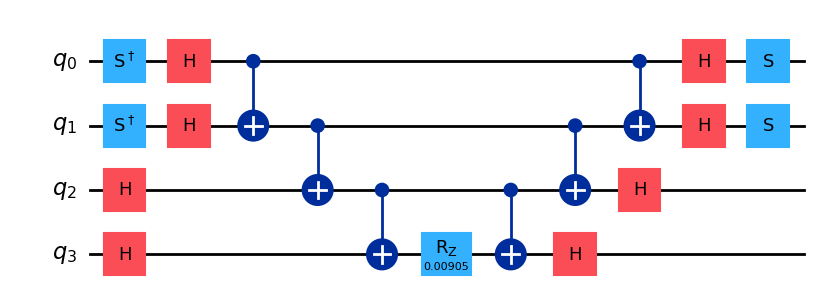

In [9]:
def pauli_rotation(label,coefficient,time):
    qc=QuantumCircuit(len(label),name=f'exp(-i {label})')
    active=[q for q,p in enumerate(reversed(label)) if p!='I']
    if not active:
        qc.global_phase=-float(coefficient)*time
        return qc
    for q,p in enumerate(reversed(label)):
        if p=='X':qc.h(q)
        elif p=='Y':qc.sdg(q);qc.h(q)
    for left,right in zip(active,active[1:]):qc.cx(left,right)
    qc.rz(2*float(coefficient)*time,active[-1])
    for left,right in reversed(list(zip(active,active[1:]))):qc.cx(left,right)
    for q,p in enumerate(reversed(label)):
        if p=='X':qc.h(q)
        elif p=='Y':qc.h(q);qc.s(q)
    return qc

TERM_LABEL='XXYY'
TERM_COEFF=float(PAULI.coeffs[PAULI.paulis.to_labels().index(TERM_LABEL)].real)
term=pauli_rotation(TERM_LABEL,TERM_COEFF,DT)
print('Term:',TERM_LABEL,'coefficient:',TERM_COEFF,'Rz angle:',2*TERM_COEFF*DT)
draw(term)
for label in ['XXYY','IIIZ','IZZI','IIII']:
    qc=pauli_rotation(label,.13,DT)
    expected=expm(-1j*.13*DT*SparsePauliOp(label).to_matrix())
    np.testing.assert_allclose(Operator(qc).data,expected,atol=1e-12)
print('Basis change / CX / Rz circuit matches each exponential, including global phase')

### 課題5：Pauli回転の角度と向き

1. Rzの角度をcτにしてはいけない理由は何か。
2. XXYYの4文字をq₀から順に適用してよいか。
3. 1項の回路が厳密なら、全Hの回路も自動的に厳密か。

<details><summary>解答例</summary>

1. Rz(α)=exp(−iαZ/2)で、α=2cτとする必要があるためです。
2. Qiskitはq₃q₂q₁q₀順なので、右端からq₀へ対応させます。この例はq₀,q₁がYです。
3. いいえ。異なるPauli項が非可換なら、各指数関数の積は和の指数関数と異なります。ここからTrotter近似が入ります。

</details>

## 6．Pauli項の回路を並べてTrotter発展を作る

一歩Δtをs分割し、$\tau=\Delta t/s$とします。時間順にj=1→Jを適用する一次ステップは
$$V_1(\tau)=e^{-ic_JP_J\tau}\cdots e^{-ic_1P_1\tau},\quad U_T=V_1(\tau)^s.$$
行列は右端が最初のゲートです。二次は半時間の順方向と逆方向を対称に並べます。

```text
一次: [P1回転(τ)] → [P2回転(τ)] → ... → [PJ回転(τ)]          × s
二次: [P1(τ/2)] → ... → [PJ(τ/2)] → [PJ(τ/2)] → ... → [P1(τ/2)] × s
```

一歩のΔtを固定すると、一般に一次の誤差はO(Δt²/s)、二次はO(Δt³/s²)です。
分割を増やすと誤差が減る一方、ゲート数が増えます。これはJW変換の誤差ではなく、非可換な時間発展を積へ分ける誤差です。

次セルではSDKで回路を生成し、独立にPauli行列を掛けた結果と照合します。
`PauliEvolutionGate`は指定した積公式で**分解した後**に評価します。
分解前の抽象ゲートを`Operator`へ渡すと厳密な指数関数が得られるため、Trotter誤差の評価には使いません。

In [10]:
def build_trotter(slices=1,order=2):
    if not isinstance(slices,int) or slices<1 or order not in (1,2):
        raise ValueError('slices>=1 and order=1 or 2')
    formula=LieTrotter(reps=slices) if order==1 else SuzukiTrotter(order=2,reps=slices)
    qc=QuantumCircuit(4)
    qc.append(PauliEvolutionGate(PAULI,time=DT,synthesis=formula),range(4))
    return qc.decompose()

def dense_product(slices,order):
    terms=list(zip(PAULI.paulis.to_labels(),PAULI.coeffs.real))
    sequence=terms+terms[::-1] if order==2 else terms
    tau=DT/slices/(2 if order==2 else 1)
    step=np.eye(16,dtype=complex)
    for label,coeff in sequence:
        p=SparsePauliOp(label).to_matrix()
        step=(np.cos(coeff*tau)*np.eye(16)-1j*np.sin(coeff*tau)*p)@step
    return np.linalg.matrix_power(step,slices)

SLICES=1  # 1, 4, 16を比較
ORDER=2   # 1または2
trotter=build_trotter(SLICES,ORDER)
UT=Operator(trotter).data
np.testing.assert_allclose(UT,dense_product(SLICES,ORDER),atol=1e-11)
compiled=transpile(trotter,basis_gates=['rz','sx','x','cx'],optimization_level=1,seed_transpiler=7)
np.testing.assert_allclose(Operator(compiled).data,UT,atol=1e-10)
np.testing.assert_allclose(UT.conj().T@UT,np.eye(16),atol=1e-11)
print('Operator fidelity:',abs(np.trace(U.conj().T@UT)/16)**2)
print('Relative operator error:',np.linalg.norm(UT-U)/np.linalg.norm(U))
print('One step CX:',compiled.count_ops().get('cx',0),'depth:',compiled.depth())

Operator fidelity: 0.999999999966299
Relative operator error: 5.804694381397656e-06
One step CX: 62 depth: 109


### 6.1．分割数・次数と回路費用を比較する

operator fidelityを$|\mathrm{Tr}(U^\dagger U_T)/16|^2$と定義します。
全16次元での指標なので、特定の二状態のギャップの精度を直接保証しません。
次セルでは同じΔtで次数と分割数だけを変え、誤差とCX数を比較します。
数値は全結合の基底ゲートrz/sx/x/cx・最適化レベル1・seed=7の条件です。実機配置は含みません。

In [11]:
RESOURCE_ROWS=[]
print('order slices  operator fidelity       relative error   CX   depth')
for order in [1,2]:
    for slices in [1,4,16]:
        qc=build_trotter(slices,order);mat=Operator(qc).data
        np.testing.assert_allclose(mat,dense_product(slices,order),atol=1e-11)
        native=transpile(qc,basis_gates=['rz','sx','x','cx'],optimization_level=1,seed_transpiler=7)
        fidelity=float(abs(np.trace(U.conj().T@mat)/16)**2)
        error=float(np.linalg.norm(mat-U)/np.linalg.norm(U))
        row=(order,slices,fidelity,error,int(native.count_ops().get('cx',0)),native.depth())
        RESOURCE_ROWS.append(row)
        print(f'{order:5d} {slices:6d} {fidelity:.14f} {error:15.6g} {row[4]:5d} {row[5]:7d}')

order slices  operator fidelity       relative error   CX   depth
    1      1 0.99999986808354     0.000363203    32      58
    1      4 0.99999999176032     9.07726e-05   128     223
    1     16 0.99999999948499     2.26927e-05   512     883
    2      1 0.99999999996630     5.80469e-06    62     109
    2      4 0.99999999999985     3.62605e-07   248     433
    2     16 0.99999999999990     2.26621e-08   992    1729


### 課題6：何を増やすと何が改善するか

1. 次数2・1分割のoperator fidelityとCX数を表から読む。
2. 分割数を増やして減るのは状態準備の誤差か、時間発展の誤差か。
3. SLICES=16とL=16は同じ操作か。

<details><summary>解答例</summary>

1. この条件ではoperator fidelity≈0.999999999966、CX=62です。値は一歩DT=0.1についてのものです。
2. 準備は常に厳密なので、変わるのは発展のTrotter誤差とゲート数です。
3. SLICESは一歩DT内の分割、Lは一歩の回路の反復です。SLICESを増やしても総時間はDT、L=16なら総時間は16DTです。

</details>

## 7．発展だけを差し替え、同じBPDEで比較する

準備$A_j$と逆準備$A_j^\dagger$、時間、位相補正は保ち、UをU_Tへ差し替えます。
$$a_k=\langle\psi_k|U_T^L|\psi_k\rangle,\qquad P_T(0^5)=|a_0+e^{i\varepsilon t}a_j|^2/4.$$
厳密準備でも、元の固有状態が近似U_Tの固有状態とは限らず、自己相関の高さと位相の両方が変わり得ます。

次セルでTARGETとLを変えて比較します。左図は信号、右図は厳密発展との差で、小さな変化も確認できます。
この小さなH₂・短時間では2本がほぼ重なって見える場合があります。
コード内の行列べきは検証のための古典的な計算です。実回路では同じ一歩の回路をL回使い、発展部分の費用もL倍です。

Max probability difference: 3.87694756847079e-05
Evolution CX only (before whole-circuit optimization): 1984


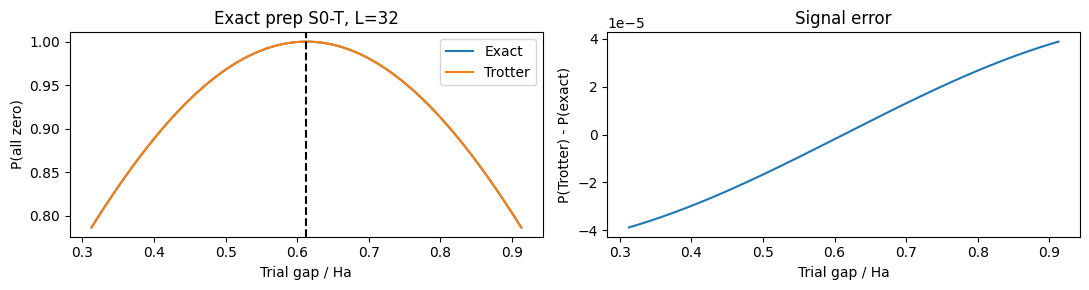

In [12]:
L=32  # 1, 32, 128を比較。TARGETは第3節で選ぶ
width=min(.3,np.pi/(L*DT))
trial=np.linspace(max(0,GAPS[TARGET]-width),GAPS[TARGET]+width,161)
curves={}
for name,u in [('Exact',U),('Trotter',UT)]:
    power=np.linalg.matrix_power(u,L)
    a0,aj=[np.vdot(STATES[k],power@STATES[k]) for k in ['S0',TARGET]]
    curves[name]=abs(a0+np.exp(1j*trial*L*DT)*aj)**2/4
    for eps in [trial[0],GAPS[TARGET],trial[-1]]:
        circuit_p=bpde_probability(TARGET,theta,u,L,float(eps*L*DT),True)
        formula_p=abs(a0+np.exp(1j*eps*L*DT)*aj)**2/4
        np.testing.assert_allclose(circuit_p,formula_p,atol=1e-10)
fig,axes=plt.subplots(1,2,figsize=(11,3))
for name,p in curves.items():axes[0].plot(trial,p,label=name)
axes[0].axvline(GAPS[TARGET],color='black',ls='--');axes[0].legend()
axes[0].set(xlabel='Trial gap / Ha',ylabel='P(all zero)',title=f'Exact prep S0-{TARGET}, L={L}')
axes[1].plot(trial,curves['Trotter']-curves['Exact'])
axes[1].set(xlabel='Trial gap / Ha',ylabel='P(Trotter) - P(exact)',title='Signal error')
plt.tight_layout();plt.show();plt.close(fig)
print('Max probability difference:',float(np.max(abs(curves['Trotter']-curves['Exact']))))
print('Evolution CX only (before whole-circuit optimization):',L*compiled.count_ops().get('cx',0))

### 課題7：BPDEの結果と誤差を結ぶ

1. TARGETをS₁・S₂・T₀へ変える。同じ発展近似なら各ギャップの誤差も同じか。
2. 長時間ほど一歩の小さな位相誤差を無視できなくなる理由は何か。
3. ユニタリ性の誤差がほぼ0なら、Trotter近似は厳密と言えるか。

<details><summary>解答例</summary>

1. 同じではありません。ギャップは二状態の位相誤差の差で決まり、状態ごとに影響が異なります。
2. 固有エネルギーのずれδEは時間t=LΔtでおよそδE tの位相差になります。
自己相関の減少や複数成分も信号を変えるため、確率差も合わせて確認します。
3. 各Pauli回転の積はユニタリですが、目標exp(−iHDT)とは異なり得ます。ユニタリ性と目標演算子への一致は別の検証です。

</details>

## 8．全回路の費用とH₄への橋渡し

発展だけのCX数に、補助の枝への準備と逆準備の費用も加える必要があります。
次セルは、選んだ一歩のTrotter回路をL回並べた**実際のBPDE回路**を短いL=1で作り、
信号式との一致と準備・逆準備込みのゲート数を表示します。
長時間のU_T^Lを別の汎用ユニタリへ再合成して費用を小さく見せることはしません。

In [13]:
def physical_bpde(target,steps,trial_gap):
    qc=PAIRS[target].copy()
    for _ in range(steps):qc.compose(trotter,range(4),inplace=True)
    qc.p(float(trial_gap)*steps*DT,4)
    qc.compose(PAIRS[target].inverse(),inplace=True)
    return qc

full=physical_bpde(TARGET,1,GAPS[TARGET])
np.testing.assert_allclose(Statevector.from_instruction(full).probabilities()[0],
    bpde_probability(TARGET,theta,UT,1,GAPS[TARGET]*DT,True),atol=1e-11)
native=transpile(full,basis_gates=['rz','sx','x','cx'],optimization_level=1,seed_transpiler=7)
np.testing.assert_allclose(Operator(native).data,Operator(full).data,atol=1e-10)
print('Full BPDE L=1 including prep/inverse:',dict(native.count_ops()),'depth:',native.depth())
print('System qubits:',4,'ancilla:',1,'measured event:', '00000')

Full BPDE L=1 including prep/inverse: {'rz': 87, 'cx': 78, 'sx': 42, 'x': 4} depth: 141
System qubits: 4 ancilla: 1 measured event: 00000


### 課題8：H₄へ持っていく検証項目

1. 本冊で厳密に保ったもの、近似したものを列挙する。
2. H₄で準備にも近似を入れる場合、何を追加で比較すべきか。
3. 準備・発展・逆準備込みの費用と、発展一歩の費用が違う理由は何か。

<details><summary>解答例</summary>

1. JW表現、4状態と枝の厳密準備、各Pauli回転を保ち、非可換な時間発展のTrotter分解だけを近似しました。
2. 状態fidelityとoperator fidelityを分け、厳密／準備のみ近似／発展のみ近似／両方近似の全0曲線を比較します。
3. 全回路には補助の枝を作る制御操作と逆準備が加わります。発展はL回反復するため、Lも費用に効きます。
次冊は系8＋補助1 qubitとなり、厳密準備やTrotter発展の費用を確認して、保存済みの近似回路を導入します。

</details>